# Natural gradient descent on a cross-entropy objective (PyTorch)

This notebook trains a small PyTorch classifier with `hybrid_ngd.torch_ngd.NGD`, minimising
cross-entropy. It compares three optimisers:

1. **Adam**, as a first-order baseline,
2. **NGD with a direct solve**, using `torch.linalg.solve`,
3. **NGD with a quantum solve**, using `QiskitHHLSolver`, which runs the HHL algorithm on a Qiskit statevector.

Each NGD step is

$$\theta \leftarrow \theta - \eta\,(F + \lambda I)^{-1}\nabla L, \qquad
L = \frac1N\sum_i \ell_i, \qquad F = \frac1N\sum_i \nabla\ell_i\,\nabla\ell_i^{\top},$$

where $\ell_i$ is the cross-entropy of sample $i$, $F$ is the *empirical Fisher* (`metric="fisher"`), and
$\lambda$ is the damping. Only the linear solve $(F+\lambda I)\,d = \nabla L$ changes between the two NGD runs.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.colors import LinearSegmentedColormap
from torch import nn

from hybrid_ngd import QiskitHHLSolver
from hybrid_ngd.torch_ngd import NGD

torch.set_default_dtype(torch.float64)
# With few clock qubits, HHL warns that small eigenvalues of F fall below its resolution.
# Section 5 shows why that is acceptable here, so the warning is silenced.
warnings.filterwarnings("ignore", message="Condition number exceeds")

In [2]:
# Plot styling. Categorical slots 1-3 identify the optimisers; a blue <-> red diverging
# pair with a grey midpoint shows the class probability.
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
COLORS = {"Adam": "#2a78d6", "NGD (direct)": "#eb6834", "NGD (HHL)": "#1baf7a"}
CLASS_COLORS = ("#2a78d6", "#e34948")
CLASS_MARKERS = ("o", "s")  # shape as well as colour, so class is never colour-only
PROBABILITY_CMAP = LinearSegmentedColormap.from_list("blue_grey_red", [CLASS_COLORS[0], "#f0efec", CLASS_COLORS[1]])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False,
})

## 1. Data: two interleaved moons

There are 200 points in two classes. They are not linearly separable, so the model needs its hidden layer.

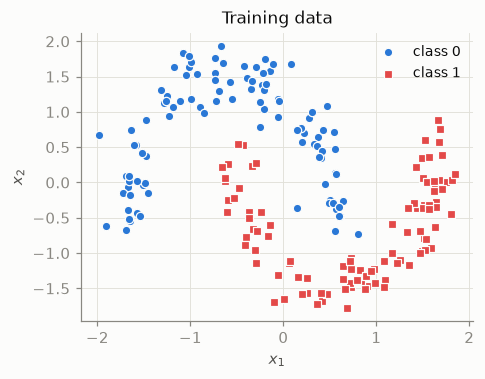

In [3]:
def two_moons(n, noise, seed):
    rng = np.random.default_rng(seed)
    t = rng.uniform(0, np.pi, n)
    labels = rng.integers(0, 2, n)
    upper = np.c_[np.cos(t), np.sin(t)]
    lower = np.c_[1 - np.cos(t), 0.5 - np.sin(t)]
    x = np.where(labels[:, None] == 0, upper, lower) + noise * rng.normal(size=(n, 2))
    x = (x - [0.5, 0.25]) / [0.9, 0.5]  # roughly centre and scale
    return torch.tensor(x), torch.tensor(labels)


X, y = two_moons(200, noise=0.12, seed=0)

fig, ax = plt.subplots(figsize=(4.6, 3.4))
for label, color in enumerate(CLASS_COLORS):
    pts = X[y == label]
    ax.scatter(pts[:, 0], pts[:, 1], s=30, color=color, marker=CLASS_MARKERS[label], edgecolor=SURFACE,
               linewidth=0.8, label=f"class {label}")
ax.set(xlabel="$x_1$", ylabel="$x_2$", title="Training data")
ax.legend(loc="upper right", fontsize=9)
plt.show()

## 2. Model, objective and the NGD closure

The model is an MLP with layers 2 → 3 → 2, giving **17 parameters**. NGD forms a dense $17\times17$ metric, and HHL
pads it to $32\times32$, which needs 5 system qubits.

`NGD.step` takes a closure that runs **only the forward pass**. With `metric="fisher"`, the closure returns the
**per-sample** losses, so use `reduction="none"` and don't call `.backward()`. The optimiser differentiates each
$\ell_i$ itself to build $F$.

```python
loss_fn = nn.CrossEntropyLoss(reduction="none")
opt = NGD(model.parameters(), lr=0.5, damping=1e-2, metric="fisher")
opt.step(lambda: loss_fn(model(X), y))   # returns the mean loss
```

In [4]:
loss_fn = nn.CrossEntropyLoss(reduction="none")


def make_model():
    torch.manual_seed(0)  # identical initial weights for every optimiser
    return nn.Sequential(nn.Linear(2, 3), nn.Tanh(), nn.Linear(3, 2))


print("parameters:", sum(p.numel() for p in make_model().parameters()))


def evaluate(model):
    with torch.no_grad():
        logits = model(X)
        return loss_fn(logits, y).mean().item(), (logits.argmax(1) == y).double().mean().item()


def train(make_optimizer, steps):
    model = make_model()
    opt = make_optimizer(model.parameters())
    loss, acc = evaluate(model)
    history = {"loss": [loss], "accuracy": [acc]}
    start = time.perf_counter()
    for _ in range(steps):
        if isinstance(opt, NGD):
            opt.step(lambda: loss_fn(model(X), y))
        else:
            opt.zero_grad()
            loss_fn(model(X), y).mean().backward()
            opt.step()
        loss, acc = evaluate(model)
        history["loss"].append(loss)
        history["accuracy"].append(acc)
    history["seconds"] = time.perf_counter() - start
    return model, history

parameters: 17


## 3. Train

Every run starts from the same weights. Both NGD runs use the same learning rate and damping. The HHL solver uses
6 clock qubits, so its circuit has 5 + 6 + 1 = 12 qubits.

In [5]:
STEPS, LR, DAMPING = 60, 0.5, 1e-2

optimizers = {
    "Adam": lambda p: torch.optim.Adam(p, lr=0.05),
    "NGD (direct)": lambda p: NGD(p, lr=LR, damping=DAMPING, metric="fisher"),
    "NGD (HHL)": lambda p: NGD(p, lr=LR, damping=DAMPING, metric="fisher", solver=QiskitHHLSolver(num_clock_qubits=6)),
}
results = {name: train(make, STEPS) for name, make in optimizers.items()}

# Adam's steps are much cheaper, so also give it 10x as many.
results_adam_long = train(optimizers["Adam"], 10 * STEPS)

def steps_to_perfect(h):
    return next((str(i) for i, a in enumerate(h["accuracy"]) if a == 1.0), "-")


print(f"{'optimiser':<16}{'steps':>6}{'final loss':>12}{'accuracy':>10}{'steps to 100%':>15}{'time (s)':>10}")
for name, (_, h) in [*results.items(), ("Adam", (None, results_adam_long[1]))]:
    print(f"{name:<16}{len(h['loss']) - 1:>6}{h['loss'][-1]:>12.4f}{h['accuracy'][-1]:>10.1%}"
          f"{steps_to_perfect(h):>15}{h['seconds']:>10.2f}")

optimiser        steps  final loss  accuracy  steps to 100%  time (s)
Adam                60      0.2699     86.5%              -      0.21
NGD (direct)        60      0.0043    100.0%             15      0.55
NGD (HHL)           60      0.0052    100.0%             31      4.21
Adam               600      0.0045    100.0%            205      2.07


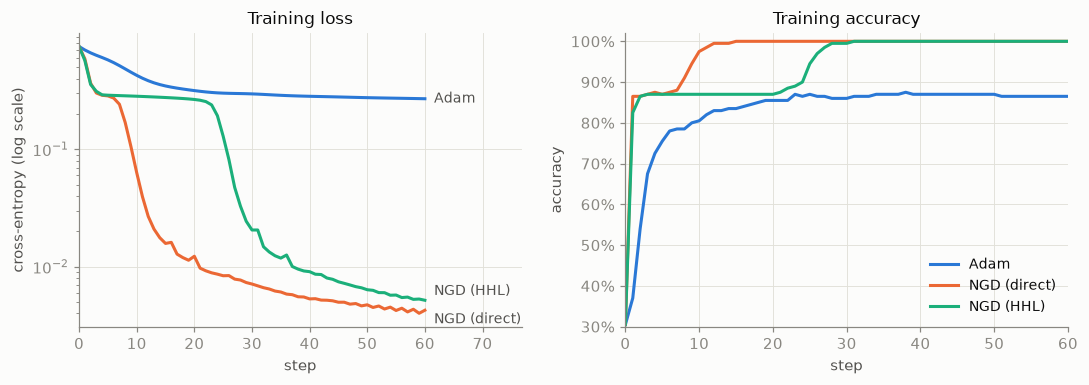

In [6]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(10, 3.6))
steps = np.arange(STEPS + 1)
# Direct labels at the line ends, nudged apart where the two NGD curves finish close together.
# The legend on the right panel carries the same identities.
label_nudge = {"Adam": 0, "NGD (direct)": -6, "NGD (HHL)": 6}
for name, (_, h) in results.items():
    for ax, key in [(ax_loss, "loss"), (ax_acc, "accuracy")]:
        ax.plot(steps, h[key], color=COLORS[name], label=name)
    ax_loss.annotate(name, (STEPS, h["loss"][-1]), xytext=(6, label_nudge[name]), textcoords="offset points",
                     va="center", fontsize=9, color=INK_2)

lowest_accuracy = min(min(h["accuracy"]) for _, h in results.values())
ax_loss.set(yscale="log", xlabel="step", ylabel="cross-entropy (log scale)", title="Training loss",
            xlim=(0, STEPS * 1.28))
ax_acc.set(xlabel="step", ylabel="accuracy", title="Training accuracy",
           xlim=(0, STEPS), ylim=(np.floor(lowest_accuracy * 10) / 10, 1.02))
ax_acc.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax_acc.legend(loc="lower right", fontsize=9)
fig.tight_layout()
plt.show()

## 4. Decision boundaries

Each panel shades the model's probability of class 1 and draws the 50% boundary.

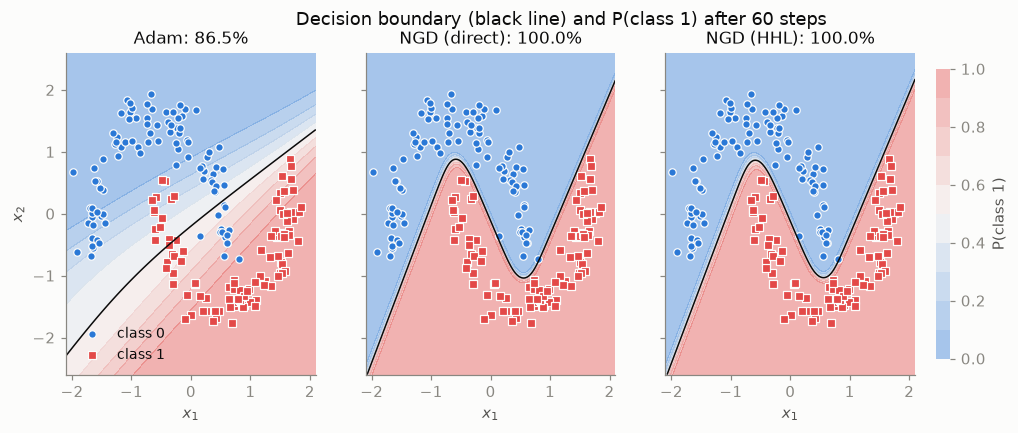

In [7]:
g1, g2 = np.meshgrid(np.linspace(-2.1, 2.1, 250), np.linspace(-2.6, 2.6, 250))
grid = torch.tensor(np.c_[g1.ravel(), g2.ravel()])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True, sharey=True)
for ax, (name, (model, h)) in zip(axes, results.items()):
    with torch.no_grad():
        p1 = torch.softmax(model(grid), dim=1)[:, 1].reshape(g1.shape).numpy()
    # a lightened field keeps same-class points visible on top of it
    filled = ax.contourf(g1, g2, p1, levels=np.linspace(0, 1, 11), cmap=PROBABILITY_CMAP, alpha=0.45)
    ax.contour(g1, g2, p1, levels=[0.5], colors=INK, linewidths=1)
    for label, color in enumerate(CLASS_COLORS):
        pts = X[y == label]
        ax.scatter(pts[:, 0], pts[:, 1], s=24, color=color, marker=CLASS_MARKERS[label], edgecolor=SURFACE,
                   linewidth=0.8, label=f"class {label}")
    ax.set(title=f"{name}: {h['accuracy'][-1]:.1%}", xlabel="$x_1$")
    ax.grid(False)
axes[0].set_ylabel("$x_2$")
axes[0].legend(loc="lower left", fontsize=9)
fig.suptitle(f"Decision boundary (black line) and P(class 1) after {STEPS} steps", color=INK)
cbar = fig.colorbar(filled, ax=axes, shrink=0.9, pad=0.02)
cbar.set_label("P(class 1)", color=INK_2)
cbar.outline.set_visible(False)
plt.show()

## 5. How accurate is the quantum solve?

A plain callable can serve as the solver. Here one records the linear system $(F+\lambda I)\,d=\nabla L$
from the first NGD step, so the different HHL configurations can be compared on exactly that system.

In [8]:
class RecordingSolver:
    def __init__(self):
        self.systems = []

    def __call__(self, A, b):
        self.systems.append((A.copy(), b.copy()))
        return np.linalg.solve(A, b)


recorder = RecordingSolver()
model = make_model()
NGD(model.parameters(), lr=LR, damping=DAMPING, solver=recorder).step(lambda: loss_fn(model(X), y))
A, b = recorder.systems[0]
eigenvalues = np.linalg.eigvalsh(A)
exact = np.linalg.solve(A, b)
print(f"F + damping*I: {A.shape[0]}x{A.shape[0]}, eigenvalues {eigenvalues[0]:.2e} .. {eigenvalues[-1]:.2e}, "
      f"condition number {eigenvalues[-1] / eigenvalues[0]:.0f}")

F + damping*I: 17x17, eigenvalues 1.00e-02 .. 6.78e-01, condition number 68


In [9]:
solvers = {
    "statevector, 4 clock qubits": QiskitHHLSolver(4),
    "statevector, 6 clock qubits": QiskitHHLSolver(6),
    "statevector, 8 clock qubits": QiskitHHLSolver(8),
    "statevector, 10 clock qubits": QiskitHHLSolver(10),
    "sampled (20k shots), 6 clock qubits": QiskitHHLSolver(6, backend="statevector_sampler", shots=20_000, seed=0),
}

print(f"{'HHL configuration':<38}{'qubits':>7}{'circuits':>9}{'rel. error':>11}{'cos(angle)':>11}{'P(success)':>11}{'time (s)':>9}")
for name, solver in solvers.items():
    start = time.perf_counter()
    x = solver(A, b)
    seconds = time.perf_counter() - start
    info = solver.last_info
    rel_error = np.linalg.norm(x - exact) / np.linalg.norm(exact)
    cosine = x @ exact / (np.linalg.norm(x) * np.linalg.norm(exact))
    print(f"{name:<38}{info.num_qubits:>7}{info.num_circuits:>9}{rel_error:>11.3f}{cosine:>11.3f}"
          f"{info.success_probability:>11.1e}{seconds:>9.2f}")

HHL configuration                      qubits circuits rel. error cos(angle) P(success) time (s)
statevector, 4 clock qubits                10        1      0.353      0.938    1.5e-01     0.05
statevector, 6 clock qubits                12        1      0.275      0.962    9.1e-03     0.03


statevector, 8 clock qubits                14        1      0.015      1.000    6.2e-04     0.30


statevector, 10 clock qubits               16        1      0.005      1.000    3.8e-05     0.99


sampled (20k shots), 6 clock qubits        12       32      0.308      0.952    9.7e-03     3.52


HHL reads the clock register as a signed integer, so it resolves eigenvalues only in steps of
$\max|\lambda| / (2^{n_c-1}-1)$ and drops those below half a step. The plot shows where that cut-off falls for
each clock size, against the spectrum of $F+\lambda I$.

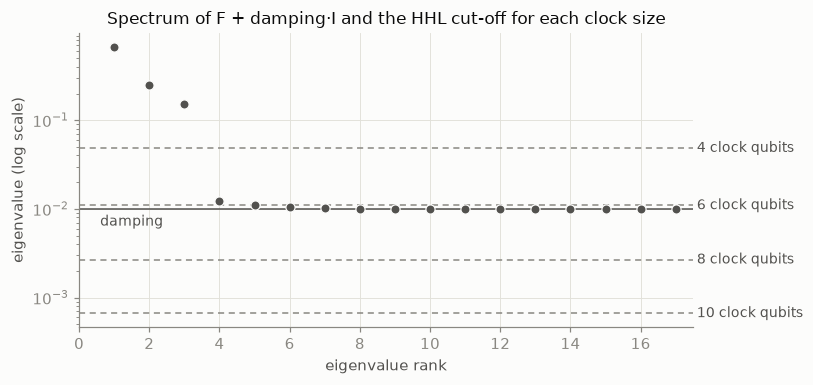

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ranks = np.arange(1, len(eigenvalues) + 1)
ax.scatter(ranks, eigenvalues[::-1], s=36, color=INK_2, edgecolor=SURFACE, linewidth=0.8, zorder=3)
for nc in (4, 6, 8, 10):
    cutoff = eigenvalues[-1] / (2 ** (nc - 1) - 1) / 2
    ax.axhline(cutoff, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    ax.annotate(f"{nc} clock qubits", (len(eigenvalues) + 0.6, cutoff), va="center", fontsize=9, color=INK_2,
                annotation_clip=False)
ax.axhline(DAMPING, color=INK_2, linewidth=1)
ax.annotate("damping", (0.6, DAMPING), xytext=(0, -11), textcoords="offset points", fontsize=9, color=INK_2)
ax.set(yscale="log", xlabel="eigenvalue rank", ylabel="eigenvalue (log scale)",
       title="Spectrum of F + damping·I and the HHL cut-off for each clock size", xlim=(0, len(eigenvalues) + 0.5))
fig.tight_layout()
plt.show()

## Takeaways

- **NGD versus Adam.** Over the same 60 steps, NGD reached 100% training accuracy, after 15 steps with the direct
  solve. Adam stalled on a plateau at 86.5% and needed about 205 steps to get there. An NGD step costs more,
  because it needs the Jacobian of every per-sample loss and a $17\times17$ solve, but each step does far more work.
- **HHL with 6 clock qubits trains just as well, though each solve is about 28% off.** The spectrum plot
  explains this. $F$ has three informative eigenvalues; the other 14 are essentially the damping, and they sit
  at the 6-qubit cut-off. HHL inverts the informative directions and largely discards the rest, so it acts like a
  truncated pseudo-inverse rather than a damped inverse. It left the plateau later (100% at step 31 rather than
  15) but finished at the same loss.
- **Precision costs success probability.** More clock qubits make the solve accurate: 1.5% error at 8 and 0.5%
  at 10. But $P(\text{success})$ falls roughly 15× for every two qubits added, because $C/\lambda$ shrinks. A
  statevector doesn't care. A shot-based backend does: at 8 clock qubits, only about 12 of 20,000 shots survive
  postselection. The sampled 6-qubit solve, which takes 32 circuits for sign recovery, agrees with the exact
  6-qubit solve up to shot noise.
- **Empirical Fisher.** `metric="fisher"` uses outer products of per-sample gradients at the *observed* labels.
  That is not the model's true Fisher, and it needs damping. Try `damping=1e-3, lr=1.0` to see training go
  unstable.

To see device noise, try `QiskitHHLSolver(6, backend="aer", shots=...)` or
`backend=AerSimulator.from_backend(FakeSherbrooke())`. The README lists every backend option.